In [1]:
from src.datasets import ALL_DATASETS
from src.experiments import ExperimentConfig, run_experiment

In [2]:
BIRCH = ["birch1", "birch2", "birch3"]
FAST_DATASETS = [d for d in ALL_DATASETS if d not in BIRCH]

In [3]:
cfg_fast = ExperimentConfig(
    name="full_fuzzy_m105_15",
    datasets=FAST_DATASETS,
    settings=["fixed", "variable"],
    methods=["Fuzzy-ACE"],
    n_runs=10,
    base_seed=0,
    sampling_ratio=0.7,
    alpha_1=0.8,
    alpha_2=0.7,
    fuzzy_ace_m_range=(1.05, 1.5),
    max_instances=5000,
    n_jobs=-1,
)
raw_fast = run_experiment(cfg_fast, resume=True, verbose=True)

[full_fuzzy_m105_15] 300 runs to do (0 already stored) -> /media/marta/Dane/Sem9/FuzzyAdaptiveClusteringEnsemble/results/full_fuzzy_m105_15
  [1/300] fixed    iris               Fuzzy-ACE run 5: ARI=0.5918 NMI=0.6413 (0.0s) ok
  [2/300] fixed    iris               Fuzzy-ACE run 4: ARI=0.6113 NMI=0.6374 (0.0s) ok
  [3/300] fixed    iris               Fuzzy-ACE run 1: ARI=0.5914 NMI=0.6405 (0.0s) ok
  [4/300] fixed    iris               Fuzzy-ACE run 3: ARI=0.6104 NMI=0.6535 (0.0s) ok
  [5/300] fixed    iris               Fuzzy-ACE run 2: ARI=0.6522 NMI=0.6806 (0.0s) ok
  [6/300] fixed    iris               Fuzzy-ACE run 7: ARI=0.6101 NMI=0.6526 (0.0s) ok
  [7/300] fixed    iris               Fuzzy-ACE run 9: ARI=0.6637 NMI=0.6882 (0.0s) ok
  [8/300] fixed    wine               Fuzzy-ACE run 0: ARI=0.9134 NMI=0.8920 (0.0s) ok
  [9/300] fixed    iris               Fuzzy-ACE run 8: ARI=0.6201 NMI=0.6595 (0.0s) ok
  [10/300] fixed    wine               Fuzzy-ACE run 2: ARI=0.8483 NMI=0.8330

In [8]:
cfg_birch = ExperimentConfig(
    name="full_fuzzy_m105_15",
    datasets=BIRCH,
    settings=["fixed", "variable"],
    methods=["Fuzzy-ACE"],
    n_runs=10,
    base_seed=0,
    sampling_ratio=0.7,
    alpha_1=0.8,
    alpha_2=0.7,
    fuzzy_ace_m_range=(1.05, 1.5),
    max_instances=5000,
    n_jobs=-1,
)
raw_birch = run_experiment(cfg_birch, resume=True, verbose=True)

[full_fuzzy_m105_15] 60 runs to do (300 already stored) -> /media/marta/Dane/Sem9/FuzzyAdaptiveClusteringEnsemble/results/full_fuzzy_m105_15
  [1/60] fixed    birch2             Fuzzy-ACE run 4: ARI=0.6863 NMI=0.9206 (413.9s) ok
  [2/60] fixed    birch2             Fuzzy-ACE run 5: ARI=0.7098 NMI=0.9223 (457.4s) ok
  [3/60] fixed    birch2             Fuzzy-ACE run 3: ARI=0.6852 NMI=0.9102 (465.8s) ok
  [4/60] fixed    birch2             Fuzzy-ACE run 1: ARI=0.5457 NMI=0.8501 (476.9s) ok
  [5/60] fixed    birch1             Fuzzy-ACE run 6: ARI=0.6505 NMI=0.8608 (511.0s) ok
  [6/60] fixed    birch1             Fuzzy-ACE run 7: ARI=0.5842 NMI=0.8267 (548.5s) ok
  [7/60] fixed    birch1             Fuzzy-ACE run 8: ARI=0.7840 NMI=0.9198 (556.7s) ok
  [8/60] fixed    birch1             Fuzzy-ACE run 3: ARI=0.8053 NMI=0.9267 (559.5s) ok
  [9/60] fixed    birch2             Fuzzy-ACE run 0: ARI=0.6064 NMI=0.8660 (581.0s) ok
  [10/60] fixed    birch1             Fuzzy-ACE run 4: ARI=0.7064 N

In [9]:
import pandas as pd
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
KEY_COLS = ["setting", "dataset", "method", "run"]

def summarize_raw(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path).drop_duplicates(subset=KEY_COLS, keep="last")
    ok = df[df["status"] == "ok"]
    return (
        ok.groupby(["setting", "dataset", "method"])
        .agg(
            ari_mean=("ari", "mean"), ari_std=("ari", "std"),
            nmi_mean=("nmi", "mean"), nmi_std=("nmi", "std"),
            n_runs=("run", "count"),
        )
        .reset_index()
    )

s_full = summarize_raw(ROOT / "results" / "full" / "raw_results.csv")
s_tuned = summarize_raw(ROOT / "results" / "full_fuzzy_m105_15" / "raw_results.csv")

common_ds = sorted(set(s_full["dataset"]) & set(s_tuned["dataset"]))

In [10]:
def compare_table(setting: str, metric: str = "ari"):
    mean_col, std_col = f"{metric}_mean", f"{metric}_std"
    f_sub = s_full[(s_full["setting"] == setting) & (s_full["dataset"].isin(common_ds))]
    t_sub = s_tuned[(s_tuned["setting"] == setting) & (s_tuned["dataset"].isin(common_ds))]

    rows = []
    for ds in common_ds:
        def fmt(df, method):
            r = df[(df["dataset"] == ds) & (df["method"] == method)]
            if r.empty:
                return None, None
            m, s = r[mean_col].iloc[0], r[std_col].iloc[0]
            return f"{m:.4f} ± {s:.4f}", m

        ace_str, _ = fmt(f_sub, "ACE")
        fcm_str, _ = fmt(f_sub, "FCM")
        old_str, old_m = fmt(f_sub, "Fuzzy-ACE")
        new_str, new_m = fmt(t_sub, "Fuzzy-ACE")
        delta = (new_m - old_m) if (new_m is not None and old_m is not None) else None

        rows.append({
            "dataset": ds,
            "ACE": ace_str,
            "FCM (2.0)": fcm_str,
            "Fuzzy-ACE (1.5, 2.5)": old_str,
            "Fuzzy-ACE (1.05, 1.5)": new_str,
            "Delta (tuned - old)": delta,
        })

    df = pd.DataFrame(rows).set_index("dataset")
    valid = df["Delta (tuned - old)"].dropna()
    wins = int((valid > 0.001).sum())
    losses = int((valid < -0.001).sum())
    ties = len(valid) - wins - losses
    print(f"\n=== {metric.upper()} ({setting} k) | Tuned vs Old: {wins}W / {ties}T / {losses}L | Mean Delta: {valid.mean():+.4f} ===")
    display(df)

In [11]:
for setting in ("fixed", "variable"):
    compare_table(setting, "ari")
    compare_table(setting, "nmi")


=== ARI (fixed k) | Tuned vs Old: 7W / 1T / 4L | Mean Delta: +0.0697 ===


,ACE,FCM (2.0),"Fuzzy-ACE (1.5, 2.5)","Fuzzy-ACE (1.05, 1.5)",Delta (tuned - old)
dataset,,,,,
birch1,0.8064 ± 0.0872,0.7477 ± 0.0174,NaN,0.6473 ± 0.1295,NaN
breast_cancer,0.8232 ± 0.0090,0.8020 ± 0.0000,0.8168 ± 0.0160,0.8168 ± 0.0145,-0.000010
dermatology,0.7764 ± 0.0799,0.4044 ± 0.0945,0.5117 ± 0.1486,0.7253 ± 0.0597,0.213527
ecoli,0.4123 ± 0.2414,0.3752 ± 0.0123,0.4041 ± 0.0602,0.4327 ± 0.0640,0.028606
glass,0.1718 ± 0.0295,0.1534 ± 0.0011,0.1491 ± 0.0355,0.1732 ± 0.0102,0.024073
image_segmentation,0.4727 ± 0.0216,0.4974 ± 0.0021,0.4927 ± 0.0534,0.4801 ± 0.0093,-0.012617
ionosphere,0.1578 ± 0.0144,0.1587 ± 0.0000,0.1608 ± 0.0189,0.1586 ± 0.0102,-0.002214
iris,0.6193 ± 0.0284,0.6303 ± 0.0000,0.6262 ± 0.0235,0.6212 ± 0.0236,-0.005004
new_thyroid,0.5572 ± 0.0496,0.6592 ± 0.0000,0.3026 ± 0.1998,0.5691 ± 0.0299,0.266490



=== NMI (fixed k) | Tuned vs Old: 8W / 1T / 3L | Mean Delta: +0.0550 ===


,ACE,FCM (2.0),"Fuzzy-ACE (1.5, 2.5)","Fuzzy-ACE (1.05, 1.5)",Delta (tuned - old)
dataset,,,,,
birch1,0.9114 ± 0.0398,0.9141 ± 0.0057,NaN,0.8564 ± 0.0606,NaN
breast_cancer,0.7163 ± 0.0110,0.6925 ± 0.0000,0.7099 ± 0.0190,0.7095 ± 0.0179,-0.000397
dermatology,0.8727 ± 0.0412,0.5246 ± 0.0803,0.6349 ± 0.0800,0.8475 ± 0.0443,0.212627
ecoli,0.5206 ± 0.1621,0.5570 ± 0.0091,0.5721 ± 0.0265,0.5988 ± 0.0312,0.026709
glass,0.3108 ± 0.0306,0.3069 ± 0.0007,0.2818 ± 0.0380,0.3154 ± 0.0160,0.033666
image_segmentation,0.6060 ± 0.0243,0.5958 ± 0.0022,0.6106 ± 0.0457,0.6159 ± 0.0152,0.005244
ionosphere,0.1152 ± 0.0140,0.1195 ± 0.0000,0.1700 ± 0.0384,0.1163 ± 0.0107,-0.053715
iris,0.6574 ± 0.0213,0.6659 ± 0.0000,0.6607 ± 0.0211,0.6585 ± 0.0170,-0.002196
new_thyroid,0.5323 ± 0.0445,0.6245 ± 0.0000,0.3252 ± 0.1806,0.5417 ± 0.0285,0.216469



=== ARI (variable k) | Tuned vs Old: 0W / 0T / 0L | Mean Delta: +nan ===


,ACE,FCM (2.0),"Fuzzy-ACE (1.5, 2.5)","Fuzzy-ACE (1.05, 1.5)",Delta (tuned - old)
dataset,,,,,
birch1,None,None,None,0.6869 ± 0.1046,None
breast_cancer,None,None,None,0.8394 ± 0.0341,None
dermatology,None,None,None,0.6963 ± 0.1133,None
ecoli,None,None,None,0.4880 ± 0.0819,None
glass,None,None,None,0.1738 ± 0.0160,None
image_segmentation,None,None,None,0.4788 ± 0.0073,None
ionosphere,None,None,None,0.1501 ± 0.0142,None
iris,None,None,None,0.6068 ± 0.0688,None
new_thyroid,None,None,None,0.5217 ± 0.1683,None



=== NMI (variable k) | Tuned vs Old: 0W / 0T / 0L | Mean Delta: +nan ===


,ACE,FCM (2.0),"Fuzzy-ACE (1.5, 2.5)","Fuzzy-ACE (1.05, 1.5)",Delta (tuned - old)
dataset,,,,,
birch1,None,None,None,0.8770 ± 0.0469,None
breast_cancer,None,None,None,0.7379 ± 0.0421,None
dermatology,None,None,None,0.8229 ± 0.0682,None
ecoli,None,None,None,0.6197 ± 0.0218,None
glass,None,None,None,0.3132 ± 0.0315,None
image_segmentation,None,None,None,0.6066 ± 0.0091,None
ionosphere,None,None,None,0.1107 ± 0.0153,None
iris,None,None,None,0.6709 ± 0.0542,None
new_thyroid,None,None,None,0.5028 ± 0.1347,None


In [4]:
from pathlib import Path
import pandas as pd
from src.stats_tests import run_statistical_tests
from src.datasets import ALL_DATASETS, ACE_PAPER_DATASETS, FUZZY_HYPOTHESIS_DATASETS, SIPU_DATASETS

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FULL_CSV  = ROOT / "results" / "full" / "raw_results.csv"
TUNED_CSV = ROOT / "results" / "full_fuzzy_m105_15" / "raw_results.csv"
OUT_DIR   = ROOT / "results" / "full_merged"
OUT_DIR.mkdir(parents=True, exist_ok=True)

df_full = pd.read_csv(FULL_CSV)
df_tuned = pd.read_csv(TUNED_CSV)

df_tuned["method"] = "Fuzzy-ACE (tuned)"

common_datasets = [d for d in ALL_DATASETS if d in set(df_full["dataset"]) & set(df_tuned["dataset"])]
df_merged = pd.concat(
    [df_full[df_full["dataset"].isin(common_datasets)], df_tuned[df_tuned["dataset"].isin(common_datasets)]],
    ignore_index=True,
)
df_merged.to_csv(OUT_DIR / "raw_results.csv", index=False)

# Build and save summary.csv (required by run_statistical_tests)
ok = df_merged[df_merged["status"] == "ok"]
summary = (
    ok.groupby(["setting", "dataset", "method"])
    .agg(
        ari_mean=("ari", "mean"),
        ari_std=("ari", "std"),
        nmi_mean=("nmi", "mean"),
        nmi_std=("nmi", "std"),
        n_runs=("ari", "count"),
    )
    .reset_index()
)
summary.to_csv(OUT_DIR / "summary.csv", index=False)

# Now run statistical tests & CD diagrams
run_statistical_tests(str(OUT_DIR), alpha=0.1)

for tag, ds_list in [
    ("ace_paper", ACE_PAPER_DATASETS),
    ("fuzzy_hypothesis", FUZZY_HYPOTHESIS_DATASETS),
    ("sipu", SIPU_DATASETS),
]:
    sub = [d for d in ds_list if d in common_datasets]
    if len(sub) >= 3:
        run_statistical_tests(str(OUT_DIR), alpha=0.1, datasets=sub, tag=tag)

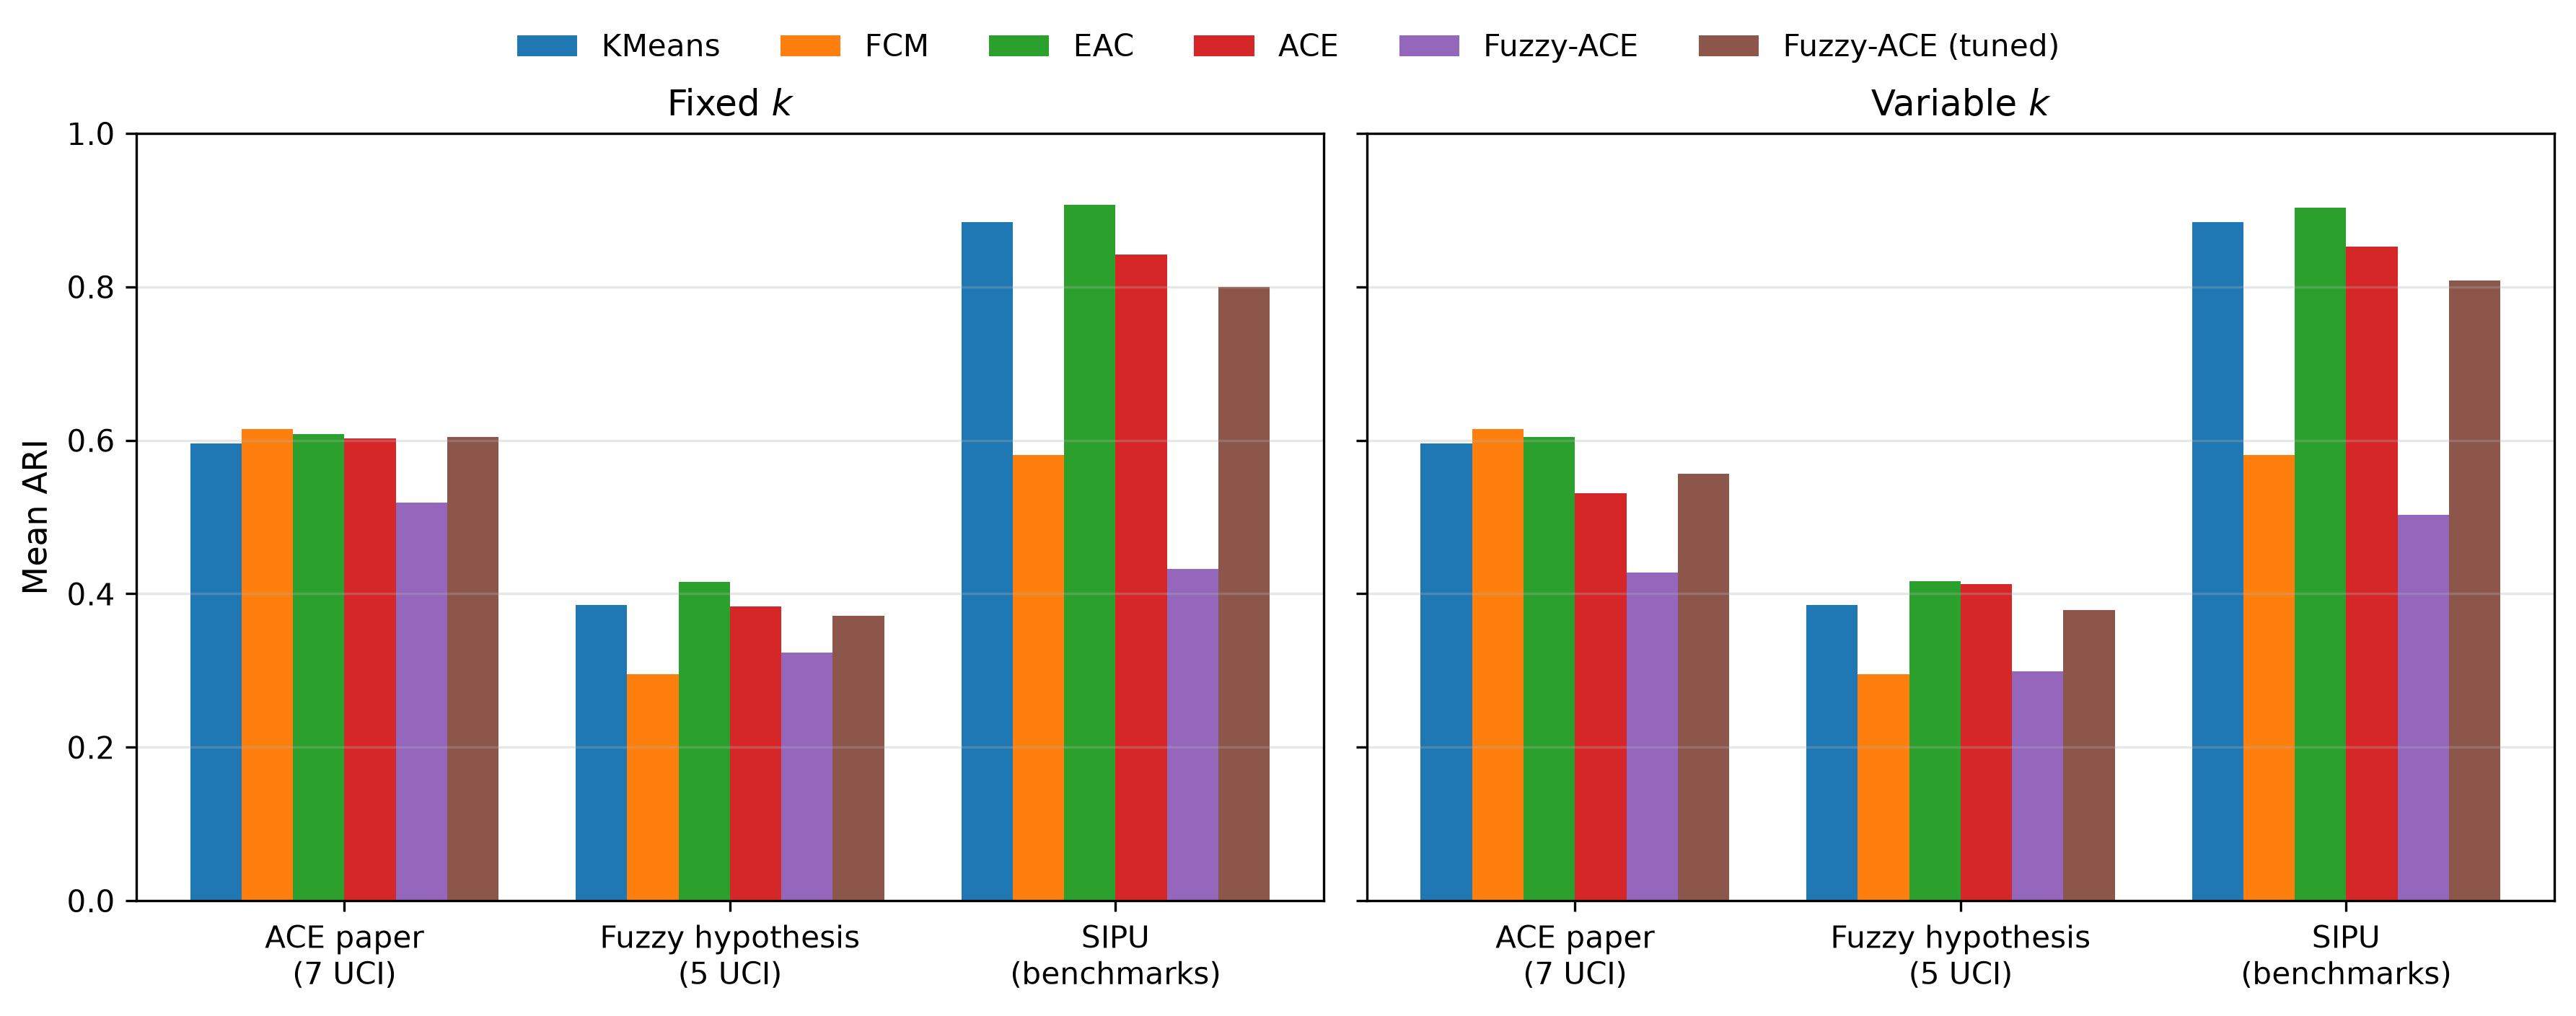

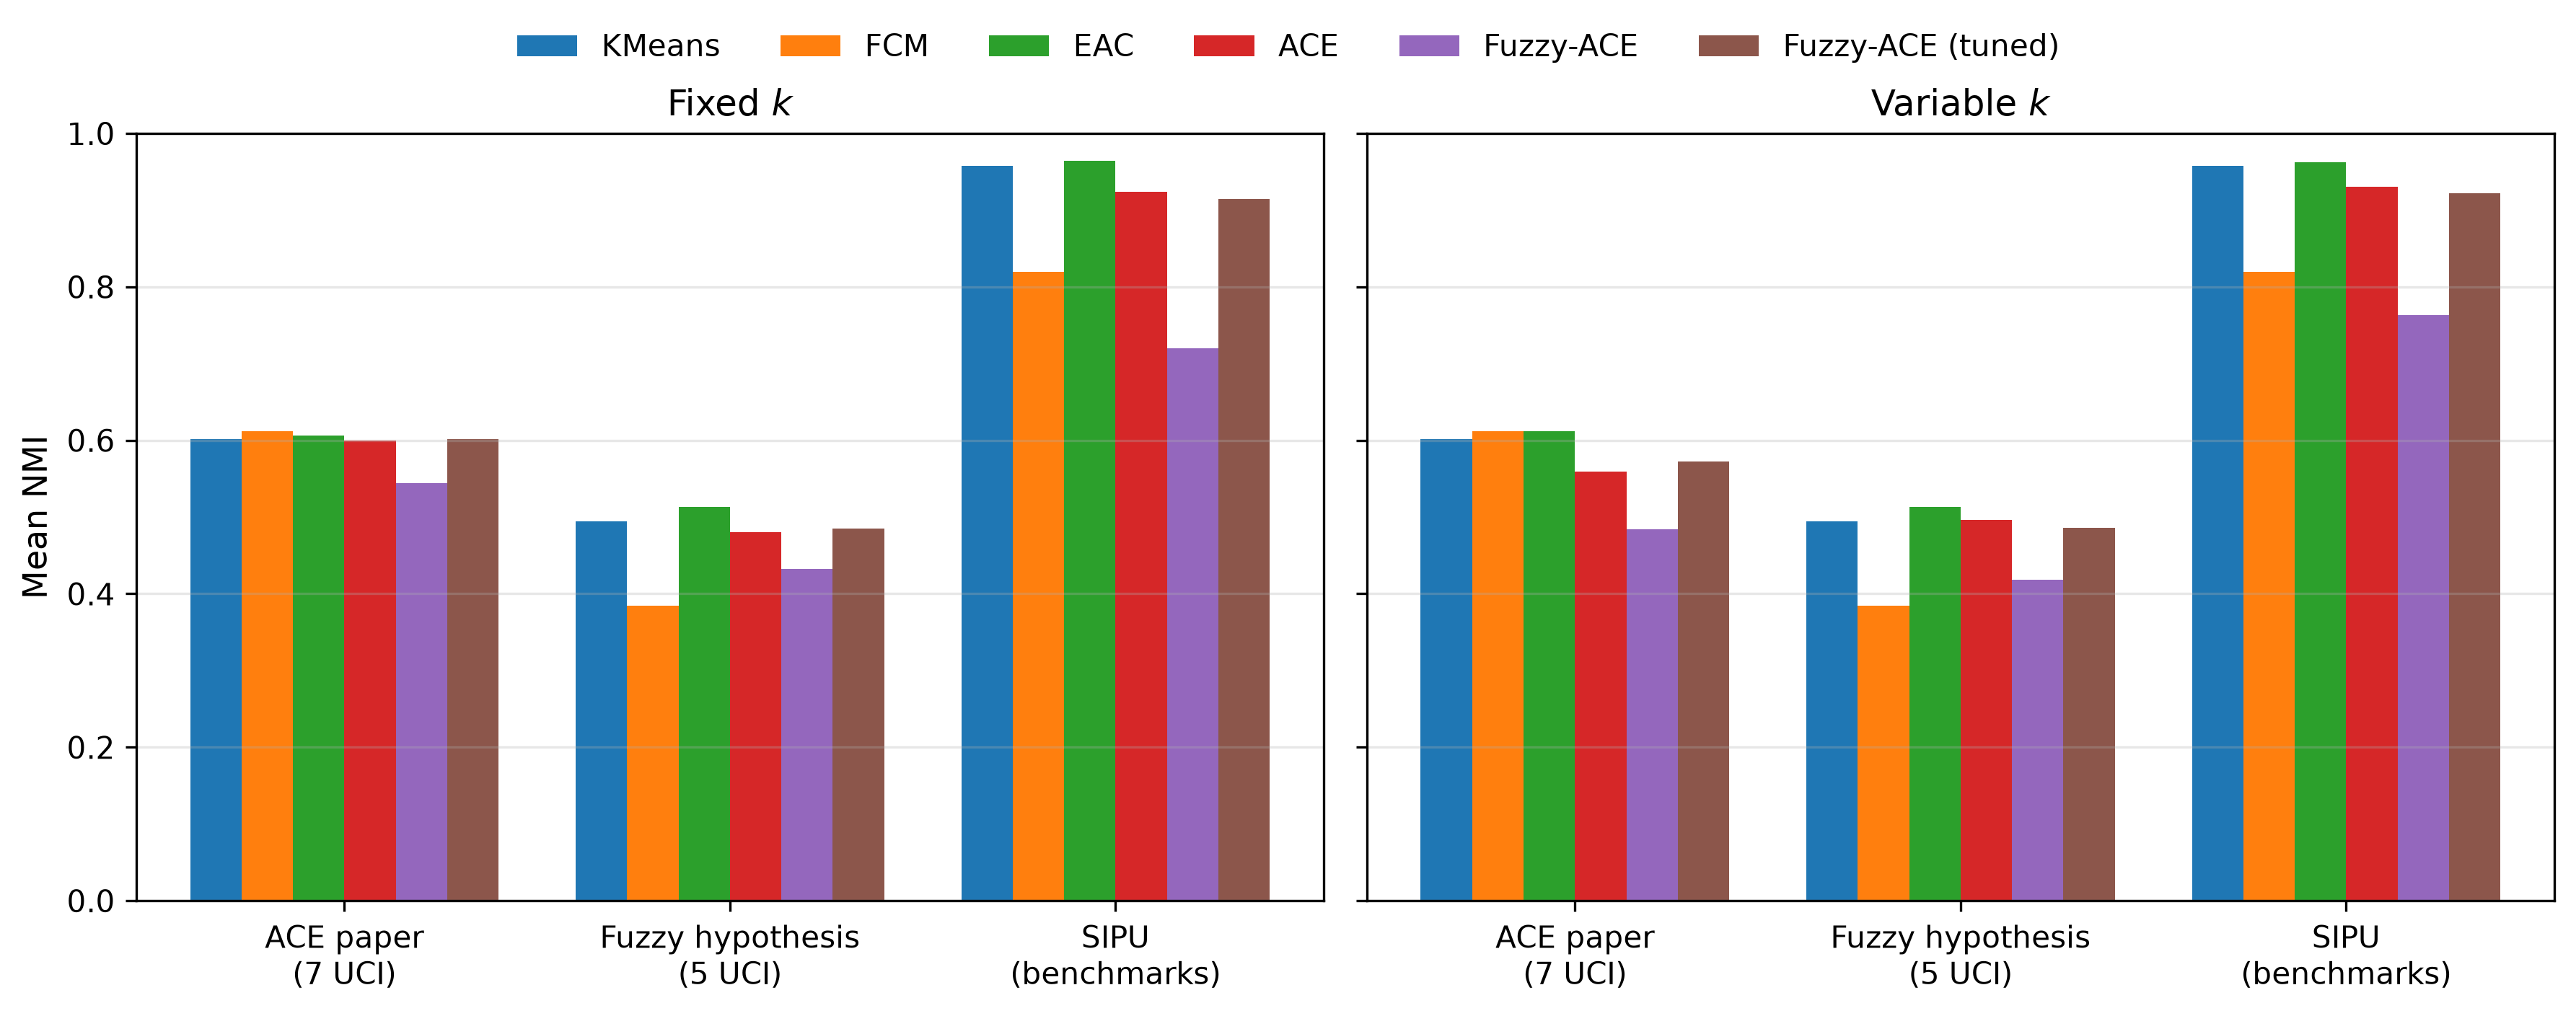

In [9]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from src.datasets import ACE_PAPER_DATASETS, FUZZY_HYPOTHESIS_DATASETS, SIPU_DATASETS

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
EXP_DIR = ROOT / "results" / "full_merged"   # or ROOT / "results" / "full"

df = pd.read_csv(EXP_DIR / "raw_results.csv")
ok = df[df["status"] == "ok"].copy()

def map_group(ds):
    if ds in ACE_PAPER_DATASETS:
        return "ACE paper\n(7 UCI)"
    if ds in FUZZY_HYPOTHESIS_DATASETS:
        return "Fuzzy hypothesis\n(5 UCI)"
    return "SIPU\n(benchmarks)"

ok["group"] = ok["dataset"].map(map_group)
groups = ["ACE paper\n(7 UCI)", "Fuzzy hypothesis\n(5 UCI)", "SIPU\n(benchmarks)"]
order = ["KMeans", "FCM", "EAC", "ACE", "Fuzzy-ACE", "Fuzzy-ACE (tuned)"]
methods = [m for m in order if m in ok["method"].unique()]

x = np.arange(len(groups))
width = 0.8 / len(methods)

for metric in ("ari", "nmi"):
    per_ds = ok.groupby(["setting", "group", "dataset", "method"])[metric].mean().reset_index()
    grp_avg = per_ds.groupby(["setting", "group", "method"])[metric].mean().reset_index()

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
    for ax, (setting, title) in zip(axes, [("fixed", "Fixed $k$"), ("variable", "Variable $k$")]):
        sub = grp_avg[grp_avg["setting"] == setting]
        for i, m in enumerate(methods):
            vals = [sub[(sub["group"] == g) & (sub["method"] == m)][metric].values[0] for g in groups]
            offset = (i - (len(methods) - 1) / 2) * width
            ax.bar(x + offset, vals, width=width, label=m)
        ax.set_title(title, fontsize=12)
        ax.set_xticks(x)
        ax.set_xticklabels(groups, fontsize=10)
        ax.set_ylim(0, 1.0)
        ax.grid(axis="y", alpha=0.3)

    axes[0].set_ylabel(f"Mean {metric.upper()}", fontsize=11)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=len(methods), bbox_to_anchor=(0.5, 1.05), frameon=False)
    fig.tight_layout()

    out_path = EXP_DIR / f"{metric}_by_group.png"
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(out_path)))

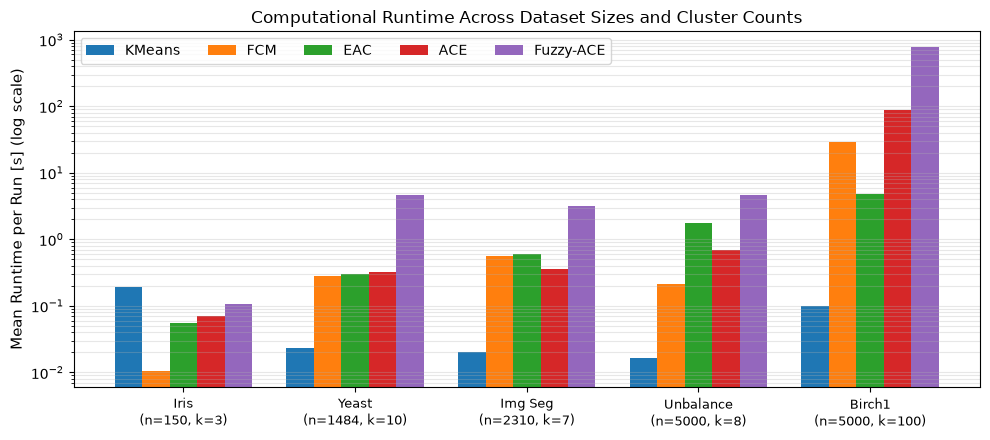

In [11]:
FULL_DIR = ROOT / "results" / "full_merged"
rt_df = pd.read_csv(FULL_DIR / "raw_results.csv")
rt_ok = rt_df[rt_df["status"] == "ok"]

rep_datasets = ["iris", "yeast", "image_segmentation", "unbalance", "birch1"]
rep_labels = ["Iris\n(n=150, k=3)", "Yeast\n(n=1484, k=10)", "Img Seg\n(n=2310, k=7)",
              "Unbalance\n(n=5000, k=8)", "Birch1\n(n=5000, k=100)"]
rt_methods = ["KMeans", "FCM", "EAC", "ACE", "Fuzzy-ACE"]

rt_mean = (
    rt_ok[rt_ok["dataset"].isin(rep_datasets)]
    .groupby(["dataset", "method"])["runtime_s"]
    .mean()
    .unstack()
    .loc[rep_datasets, rt_methods]
)

fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(rep_datasets))
width = 0.8 / len(rt_methods)

for i, m in enumerate(rt_methods):
    offset = (i - (len(rt_methods) - 1) / 2) * width
    ax.bar(x + offset, rt_mean[m].values, width=width, label=m)

ax.set_yscale("log")
ax.set_ylabel("Mean Runtime per Run [s] (log scale)", fontsize=11)
ax.set_title("Computational Runtime Across Dataset Sizes and Cluster Counts", fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(rep_labels, fontsize=9.5)
ax.grid(axis="y", which="both", alpha=0.3)
ax.legend(ncol=len(rt_methods), loc="upper left", frameon=True)

fig.tight_layout()
fig.savefig(FULL_DIR / "runtime_comparison.png", dpi=300, bbox_inches="tight")
plt.show()